# Search-space ablation: initial vs evolved forecasters

Three programs, each with a prediction plot and its **official competition score**:

1. **Initial program** -- the seed both arms started from
2. **HPO champion** -- best run from the arm that could edit only the 10 `PARAMS`
3. **Model discovery champion** -- best run from the arm that could rewrite the
   modelling functions but not `PARAMS`

Every score comes from `official_metrics.py`, the verbatim Baidu KDD Cup 2022
grader. Scored on both the 16 held-out **validation** windows (what evolution
optimised against) and the 142-window **final_phase_test** set (leaderboard
comparable). Units are MW, summed across 134 turbines. **Lower is better.**

## 1. Setup

In [1]:
import os, sys, glob, importlib.util, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)

REPO = "/home/dorsa/srip/windevolve_sdwpf"
sys.path.insert(0, REPO)
os.chdir(REPO)


import official_metrics as om
from test_data import TestData

VAL_DIR  = os.environ.get("SDWPF_VAL_WINDOWS", os.path.join(REPO, "val_split", "val_windows"))
TEST_DIR = os.environ.get("SDWPF_TEST_DIR",
    "/home/dorsa/srip/wind_forecasting_data/sdwpf_kddcup/final_phase_test")
RUNS = os.path.join(REPO, "ablation", "runs")
CAPACITY, OUTPUT_LEN, DAY_LEN = 134, 288, 144

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False})
NAVY, GOLD, GREY = "#182B49", "#C69214", "#747678"

print("repo             :", REPO)
print("validation windows:", len(glob.glob(os.path.join(VAL_DIR, "infile", "*in.csv"))))
print("test windows      :", len(glob.glob(os.path.join(TEST_DIR, "infile", "*in.csv"))))

repo             : /home/dorsa/srip/windevolve_sdwpf
validation windows: 16
test windows      : 142


## 2. Pick the three programs

The champion of each arm is the run with the best validation score. That is the
only selection rule used -- test scores play no part in choosing them.

In [2]:
def load_program(path, name="cand"):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

def score(path, window_dir, label=""):
    """Grade a program on every window in `window_dir` using the official grader."""
    mod = load_program(path)
    ins  = sorted(glob.glob(os.path.join(window_dir, "infile",  "*in.csv")))
    outs = sorted(glob.glob(os.path.join(window_dir, "outfile", "*out.csv")))
    maes, rmses = [], []
    for k, (inf, outf) in enumerate(zip(ins, outs)):
        envs = {"path_to_test_x": inf, "capacity": CAPACITY,
                "output_len": OUTPUT_LEN, "start_col": 3, "out_var": 1}
        pred = np.asarray(mod.forecast(envs), dtype=float)
        td = TestData(path_to_data=outf, start_col=3, farm_capacity=CAPACITY)
        tb, rw = td.get_all_turbines()
        settings = {"capacity": CAPACITY, "output_len": OUTPUT_LEN, "day_len": DAY_LEN,
                    "path_to_test_x": inf, "min_non_zero_ratio": 0.9,
                    "min_distinct_ratio": 0.1}
        mae, rmse, _a, _b = om.regressor_detailed_scores(
            [pred[i] for i in range(CAPACITY)],
            [np.asarray(tb[i])[:OUTPUT_LEN, -1:] for i in range(CAPACITY)],
            [rw[i].iloc[:OUTPUT_LEN].reset_index(drop=True) for i in range(CAPACITY)],
            settings)
        maes.append(mae); rmses.append(rmse)
        if label and (k + 1) % 25 == 0:
            print("   {} ... {}/{}".format(label, k + 1, len(ins)))
    return {"score": 0.5 * (np.mean(maes) + np.mean(rmses)),
            "mae": float(np.mean(maes)), "rmse": float(np.mean(rmses)),
            "n_windows": len(maes)}

# every completed run, scored on validation, to find each arm's champion
val_rows = []
for d in sorted(glob.glob(os.path.join(RUNS, "*_seed*"))):
    best = os.path.join(d, "best", "best_program.py")
    if os.path.isdir(d) and os.path.isfile(best):
        name = os.path.basename(d)
        s = score(best, VAL_DIR)
        val_rows.append({"run": name, "arm": name.split("_")[0],
                         "path": best, "val_score": s["score"]})
        print("{:<14} {:.4f} MW".format(name, s["score"]))

runs_df = pd.DataFrame(val_rows)
champs = {"initial": os.path.join(REPO, "ablation", "seed_hpo.py")}
for arm, pretty in [("hpo", "HPO"), ("model", "model discovery")]:
    sub = runs_df[runs_df.arm == arm].sort_values("val_score")
    champs[pretty] = sub.iloc[0]["path"]
    print("\n{} champion: {} ({:.4f} MW)".format(pretty, sub.iloc[0]["run"], sub.iloc[0]["val_score"]))

hpo_seed1      39.6068 MW
hpo_seed2      38.6497 MW
hpo_seed3      39.6069 MW
model_seed1    39.6627 MW
model_seed2    39.8020 MW
model_seed3    39.3036 MW

HPO champion: hpo_seed2 (38.6497 MW)

model discovery champion: model_seed3 (39.3036 MW)


## 3. Official competition scores

Both splits, all three programs. The test pass reads 142 windows per program and
takes a few minutes each.

In [3]:
SCORES = {}
for name, path in champs.items():
    print("scoring {} ...".format(name))
    v = score(path, VAL_DIR)
    t = score(path, TEST_DIR, label=name)
    SCORES[name] = {"val": v, "test": t}
    print("   validation {:.4f} MW   |   final test {:.4f} MW\n".format(
        v["score"], t["score"]))

table = pd.DataFrame([{
    "program": n,
    "val_score_MW": s["val"]["score"],
    "test_score_MW": s["test"]["score"],
    "test_rmse": s["test"]["rmse"], "test_mae": s["test"]["mae"],
    "val_windows": s["val"]["n_windows"], "test_windows": s["test"]["n_windows"],
} for n, s in SCORES.items()])

base_v = table.loc[table.program == "initial", "val_score_MW"].iloc[0]
base_t = table.loc[table.program == "initial", "test_score_MW"].iloc[0]
table["val_vs_initial"]  = table["val_score_MW"]  - base_v
table["test_vs_initial"] = table["test_score_MW"] - base_t
display(table.round(4))
table.to_csv(os.path.join(REPO, "ablation", "official_scores.csv"), index=False)

scoring initial ...
   initial ... 25/142
   initial ... 50/142
   initial ... 75/142
   initial ... 100/142
   initial ... 125/142
   validation 39.8020 MW   |   final test 48.6546 MW

scoring HPO ...
   HPO ... 25/142
   HPO ... 50/142
   HPO ... 75/142
   HPO ... 100/142
   HPO ... 125/142
   validation 38.6497 MW   |   final test 47.9883 MW

scoring model discovery ...
   model discovery ... 25/142
   model discovery ... 50/142
   model discovery ... 75/142
   model discovery ... 100/142
   model discovery ... 125/142
   validation 39.3036 MW   |   final test 47.9013 MW



,program,val_score_MW,test_score_MW,test_rmse,test_mae,val_windows,test_windows,val_vs_initial,test_vs_initial
0,initial,39.8020,48.6546,52.7728,44.5363,16,142,0.0000,0.0000
1,HPO,38.6497,47.9883,52.2041,43.7726,16,142,-1.1523,-0.6662
2,model discovery,39.3036,47.9013,52.0643,43.7382,16,142,-0.4984,-0.7533


## 4. Prediction plots

One validation window, farm-aggregate power over the 48-hour horizon. The
official score sums *per-turbine* errors, so this aggregate view shows the shape
of each forecast rather than the scored quantity itself.

In [17]:
WINDOW = 0

ins  = sorted(glob.glob(os.path.join(VAL_DIR, "infile",  "*in.csv")))
outs = sorted(glob.glob(os.path.join(VAL_DIR, "outfile", "*out.csv")))

td = TestData(path_to_data=outs[WINDOW], start_col=3, farm_capacity=CAPACITY)
tb, rw = td.get_all_turbines()
GT   = np.stack([np.asarray(tb[i])[:OUTPUT_LEN, -1] for i in range(CAPACITY)])
RAWS = [rw[i].iloc[:OUTPUT_LEN].reset_index(drop=True) for i in range(CAPACITY)]

def valid_mask(raw):
    """The official masking rule, per turbine."""
    nan_cond = pd.isna(raw).any(axis=1)
    bad = ((raw["Patv"] < 0)
           | ((raw["Patv"] == 0) & (raw["Wspd"] > 2.5))
           | (raw["Pab1"] > 89) | (raw["Pab2"] > 89) | (raw["Pab3"] > 89)
           | (raw["Wdir"] < -180) | (raw["Wdir"] > 180)
           | (raw["Ndir"] < -720) | (raw["Ndir"] > 720))
    return (~nan_cond & ~bad).to_numpy()

MASK = np.stack([valid_mask(r) for r in RAWS])
hours = np.arange(OUTPUT_LEN) / 6.0
truth_farm = np.nansum(np.where(MASK, GT, np.nan), axis=0) / 1000.0

PRED = {}
for name, path in champs.items():
    mod = load_program(path, name.replace(" ", "_"))
    envs = {"path_to_test_x": ins[WINDOW], "capacity": CAPACITY,
            "output_len": OUTPUT_LEN, "start_col": 3, "out_var": 1}
    PRED[name] = np.asarray(mod.forecast(envs), dtype=float)[:, :, 0]

print("window {}: {:.1f}% of turbine-timesteps are scored".format(
    WINDOW + 1, 100 * MASK.mean()))

window 1: 99.5% of turbine-timesteps are scored


### 4a. Initial program

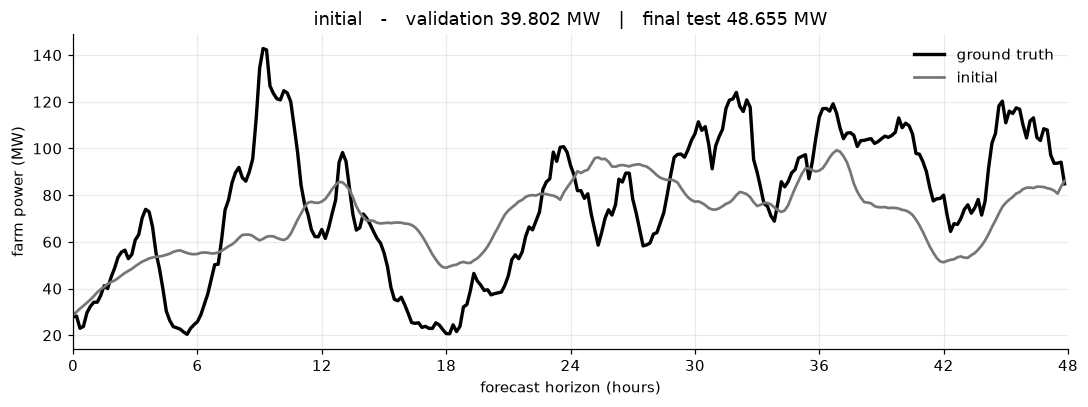

In [18]:
def plot_one(name, colour):
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.plot(hours, truth_farm, color="black", lw=2.2, label="ground truth")
    ax.plot(hours, PRED[name].sum(axis=0) / 1000.0, color=colour, lw=1.8, label=name)
    s = SCORES[name]
    ax.set_title("{}   -   validation {:.3f} MW   |   final test {:.3f} MW".format(
        name, s["val"]["score"], s["test"]["score"]))
    ax.set_xlabel("forecast horizon (hours)"); ax.set_ylabel("farm power (MW)")
    ax.set_xlim(0, 48); ax.set_xticks(np.arange(0, 49, 6))
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

plot_one("initial", GREY)

### 4b. HPO champion

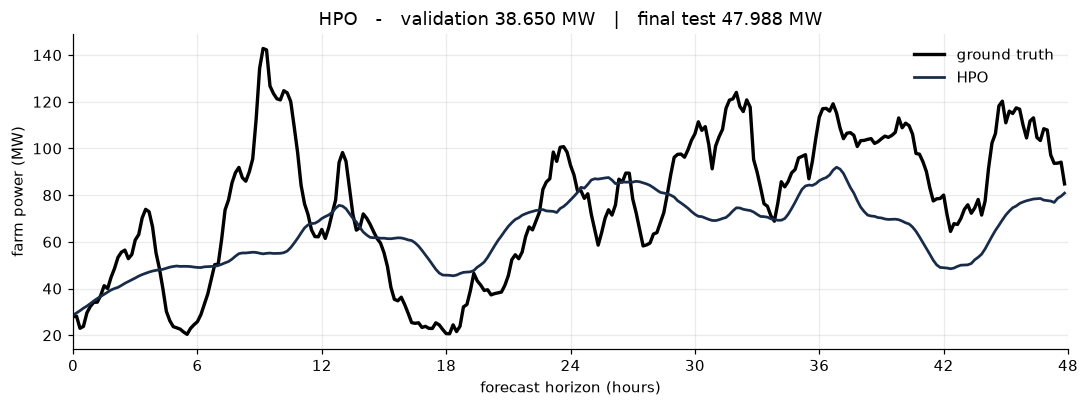

In [19]:
plot_one("HPO", NAVY)

### 4c. Model discovery champion

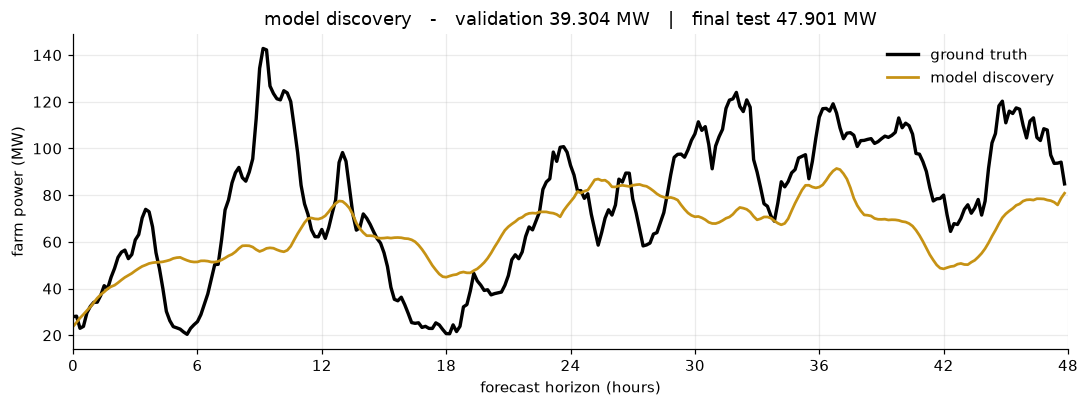

In [20]:
plot_one("model discovery", GOLD)

### 4d. All three together

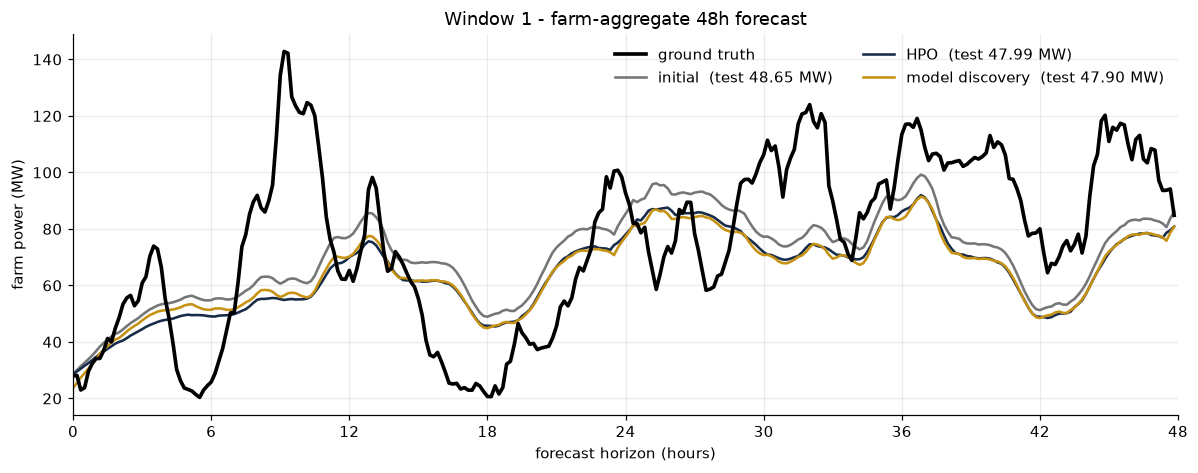

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(hours, truth_farm, color="black", lw=2.4, label="ground truth", zorder=5)
for name, colour in [("initial", GREY), ("HPO", NAVY), ("model discovery", GOLD)]:
    ax.plot(hours, PRED[name].sum(axis=0) / 1000.0, color=colour, lw=1.7,
            label="{}  (test {:.2f} MW)".format(name, SCORES[name]["test"]["score"]))
ax.set_xlabel("forecast horizon (hours)"); ax.set_ylabel("farm power (MW)")
ax.set_title("Window {} - farm-aggregate 48h forecast".format(WINDOW + 1))
ax.set_xlim(0, 48); ax.set_xticks(np.arange(0, 49, 6))
ax.legend(frameon=False, ncol=2)
plt.tight_layout(); plt.show()

## 5. Score comparison

Left: the two splits side by side. Right: change from the initial program --
below zero means the evolved program is better.

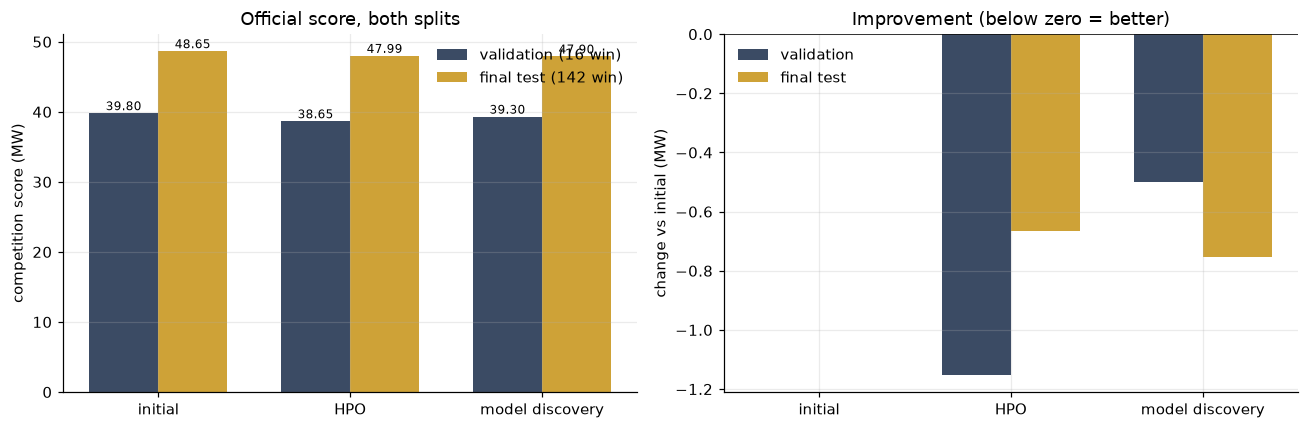

CHANGE FROM INITIAL
  HPO                validation -1.1523 MW (-2.90%)   test -0.6662 MW (-1.37%)
  model discovery    validation -0.4984 MW (-1.25%)   test -0.7533 MW (-1.55%)


In [9]:
order = ["initial", "HPO", "model discovery"]
cols  = [GREY, NAVY, GOLD]
x = np.arange(len(order)); w = 0.36

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

v = [SCORES[n]["val"]["score"] for n in order]
t = [SCORES[n]["test"]["score"] for n in order]
axes[0].bar(x - w/2, v, w, label="validation (16 win)", color=NAVY, alpha=0.85)
axes[0].bar(x + w/2, t, w, label="final test (142 win)", color=GOLD, alpha=0.85)
for i, (a, b) in enumerate(zip(v, t)):
    axes[0].text(i - w/2, a, "{:.2f}".format(a), ha="center", va="bottom", fontsize=8)
    axes[0].text(i + w/2, b, "{:.2f}".format(b), ha="center", va="bottom", fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(order)
axes[0].set_ylabel("competition score (MW)")
axes[0].set_title("Official score, both splits"); axes[0].legend(frameon=False)

dv = [SCORES[n]["val"]["score"]  - SCORES["initial"]["val"]["score"]  for n in order]
dt = [SCORES[n]["test"]["score"] - SCORES["initial"]["test"]["score"] for n in order]
axes[1].bar(x - w/2, dv, w, label="validation", color=NAVY, alpha=0.85)
axes[1].bar(x + w/2, dt, w, label="final test", color=GOLD, alpha=0.85)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xticks(x); axes[1].set_xticklabels(order)
axes[1].set_ylabel("change vs initial (MW)")
axes[1].set_title("Improvement (below zero = better)"); axes[1].legend(frameon=False)

plt.tight_layout(); plt.show()

print("CHANGE FROM INITIAL")
for n in order[1:]:
    print("  {:<18} validation {:+.4f} MW ({:+.2f}%)   test {:+.4f} MW ({:+.2f}%)".format(
        n,
        SCORES[n]["val"]["score"] - SCORES["initial"]["val"]["score"],
        100 * (SCORES[n]["val"]["score"] - SCORES["initial"]["val"]["score"]) / SCORES["initial"]["val"]["score"],
        SCORES[n]["test"]["score"] - SCORES["initial"]["test"]["score"],
        100 * (SCORES[n]["test"]["score"] - SCORES["initial"]["test"]["score"]) / SCORES["initial"]["test"]["score"]))

## 6. Did the gains hold up on the test set?

Evolution optimised the validation score. The test set is the check on whether
those gains were real or fitted to the 16 validation windows. A validation gain
that shrinks or reverses on test is the generalization gap
(Toledo et al. 2025, Sec. 5.3).

In [10]:
print("{:<18} {:>12} {:>12} {:>14}".format("program", "val gain", "test gain", "held up?"))
for n in order[1:]:
    gv = SCORES["initial"]["val"]["score"]  - SCORES[n]["val"]["score"]     # positive = better
    gt = SCORES["initial"]["test"]["score"] - SCORES[n]["test"]["score"]
    if gv <= 0:
        verdict = "no val gain"
    elif gt <= 0:
        verdict = "REVERSED"
    elif gt < 0.5 * gv:
        verdict = "shrank >50%"
    else:
        verdict = "held"
    print("{:<18} {:>12.4f} {:>12.4f} {:>14}".format(n, gv, gt, verdict))

print("\nvalidation windows: {}   test windows: {}".format(
    SCORES["initial"]["val"]["n_windows"], SCORES["initial"]["test"]["n_windows"]))

program                val gain    test gain       held up?
HPO                      1.1523       0.6662           held
model discovery          0.4984       0.7533           held

validation windows: 16   test windows: 142


## 7. What changed in each program

In [11]:
import subprocess, re

print("=" * 70)
print("HPO -- parameter changes")
print("=" * 70)
def read_params(path):
    src = open(path).read()
    blk = re.search(r"PARAMS\s*=\s*\{(.*?)\}", src, re.S)
    return {k: float(v) for k, v in re.findall(r'"(\w+)":\s*([0-9.eE+-]+)', blk.group(1))} if blk else {}

base = read_params(champs["initial"])
evolved = read_params(champs["HPO"])
rows = [{"param": k, "initial": v, "evolved": evolved.get(k, np.nan),
         "changed": abs(evolved.get(k, v) - v) > 1e-12} for k, v in base.items()]
display(pd.DataFrame(rows))
print("{} of {} parameters changed".format(sum(r["changed"] for r in rows), len(rows)))

print("\n" + "=" * 70)
print("MODEL DISCOVERY -- structural changes")
print("=" * 70)
seed_model = os.path.join(REPO, "ablation", "seed_model.py")
print(subprocess.run(["diff", seed_model, champs["model discovery"]],
                     capture_output=True, text=True).stdout)

HPO -- parameter changes


,param,initial,evolved,changed
0,recent_window,36.000,52.000,True
1,recent_halflife,12.000,10.000,True
2,decay_hours,8.000,10.000,True
3,weight_floor,0.050,0.015,True
4,diurnal_days,10.000,10.000,False
5,diurnal_smooth,5.000,7.000,True
6,diurnal_min_days,3.000,3.000,False
7,clip_quantile,0.995,0.985,True
8,level_shrink,1.000,1.020,True
9,profile_shrink,1.000,0.920,True


8 of 10 parameters changed

MODEL DISCOVERY -- structural changes
84c84
< def _recent_level(power, params):
---
> def _recent_level(power, wspd, params):
94a95,111
>     
>     # Normalize recent wind speed and use power curve proxy
>     wspd_tail = wspd[:, -win:]
>     wspd_valid = np.isfinite(wspd_tail)
>     wspd_sum = (w * np.where(wspd_valid, wspd_tail, 0.0)).sum(axis=1)
>     wspd_count = (w * wspd_valid).sum(axis=1)
>     recent_wspd = np.where(wspd_count > 0, wspd_sum / np.maximum(wspd_count, 1e-9), 0.0)
>     
>     # Use cubic power curve (cut-in ~3.0 m/s, rated ~12 m/s) tuned for typical turbines
>     wspd_norm = np.clip((recent_wspd - 3.0) / 9.0, 0.0, 1.0)  # normalized to [0, 1]
>     wspd_power = wspd_norm ** 3.0
>     # Per-turbine scale: use 76th percentile of historical power for each turbine
>     turbine_scale = np.quantile(np.where(np.isfinite(power), power, 0.0), 0.76, axis=1)
>     turbine_scale = np.maximum(turbine_scale, 50.0)  # floor at 50 kW
>     # Blend w

## 8. Reading the results

Fill in from the numbers above.

**What the comparison is.** Both arms started from the identical program, scoring
the same on validation to 16 decimals. Same evaluator, same 16 validation
windows, same 40 iterations, same model (Claude Haiku 4.5), same islands and
population. The only difference was which region of the seed file the loop could
rewrite.

**The spaces are nested.** The model arm could hardcode any constant a parameter
could hold, so it can reach everything HPO can plus more. If it did not do better,
that is not a limitation of search-space size.

**Caveats to state:** Claude Haiku 4.5, 16 validation windows, 40 iterations,
n=3 seeds per arm. Toledo et al. App. I recommend 10 seeds minimum for ranking
claims, so if the per-arm ranges overlap the honest statement is "no separation
detected at n=3", not that one arm won.

**Not comparable** to the earlier Gemini runs, or to the baseline table -- those
were measured on a different setup. To anchor against the baselines, score them
through this same notebook's `score()` on the same windows.